In [30]:
import pathlib

import numpy as np
import xarray as xr
import verde as vd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter, binary_dilation, distance_transform_edt
from scipy.spatial import cKDTree
from pyproj import Transformer
from tqdm.auto import tqdm

#myProj = Proj("+proj=stere +lat_0=-90 +lat_ts=-71")

In [3]:
# cut out region bigger than inversion area
xmin_inv = 2.45e6 /1000
xmax_inv = 2.57e6 /1000
ymin_inv = -0.49e6  /1000
ymax_inv = -0.36e6 /1000

xmin_prepro = xmin_inv - 1e5/1000
xmax_prepro = xmax_inv + 1e5/1000
ymin_prepro = ymin_inv - 1e5/1000
ymax_prepro = ymax_inv + 1e5/1000

In [5]:
path = "data/Bedmachine/BedMachineAntarctica-v3.nc"

region = (xmin_prepro, xmax_prepro, ymin_prepro, ymax_prepro)
west, east, south, north = region  # EPSG:3031 coordinates in km

median_vars = ("bed", "surface", "thick")
nearest_vars = ("mask", "geoid", "source", "dataid", "errbed")
variables = median_vars + nearest_vars


with xr.open_dataset(path) as raw:
    raw = raw.rename({
        "x": "easting",
        "y": "northing",
        "thickness": "thick"})
    raw = raw.assign_coords(easting=raw.easting / 1000,northing=raw.northing / 1000,)
    aoi = raw[list(variables)].isel(easting=(raw.easting > west) & (raw.easting < east),northing=(raw.northing > south) 
                                    & (raw.northing < north)).transpose("northing", "easting").load()

aoi.easting.attrs["units"] = "km"
aoi.northing.attrs["units"] = "km"

xx, yy = np.meshgrid(aoi.easting.values, aoi.northing.values)
coordinates = (xx, yy)
tree = cKDTree(np.column_stack((xx.ravel(), yy.ravel())))


def resample_bedmachine(spacing):
    """Block medians plus nearest-neighbour sampling; spacing in km."""
    reducer = vd.BlockReduce(reduction="median",spacing=spacing,region=region,adjust="region",center_coordinates=True,)
    coords, reduced = reducer.filter(coordinates,tuple(aoi[name].values for name in median_vars))
    _, indices = tree.query(np.column_stack(coords), k=1)
    values = dict(zip(median_vars, reduced))
    values.update({name: aoi[name].values.ravel()[indices] for name in nearest_vars})

    result = xr.Dataset({name: ("point", np.asarray(value).ravel())
         for name, value in values.items()},
        coords={"easting": ("point", coords[0]),"northing": ("point", coords[1]),},).set_index(point=["northing", "easting"]
    ).unstack("point").transpose("northing", "easting")

    for name in variables:
        result[name].attrs = aoi[name].attrs.copy()
    result.easting.attrs["units"] = "km"
    result.northing.attrs["units"] = "km"
    return result

# decide on which resolution you would like to have the results
#ds_1k = resample_bedmachine(1) # 1 km 
#ds_2k = resample_bedmachine(2) # 2 km 
ds  = aoi.copy() # 500 m BedMachine resolution

In [8]:
ds_run_2k = xr.load_dataset(pathlib.Path(f'processed_data/xr_2000.nc'))
ds_run_1k = xr.load_dataset(pathlib.Path(f'processed_data/xr_1000.nc'))

def load_results(folder):
    prefixes = {
        "beds": "beds",
        "beds_std": "std_beds",
        "rmse": "rmse",
        "grav": "result_grav",
        "target": "target_filt",}
    return {name: np.load(pathlib.Path(folder) / f"{prefix}.npy", mmap_mode="r")
        for name, prefix in prefixes.items()}
    
regional = load_results("Results/Regional")
local = load_results("Results/Local")

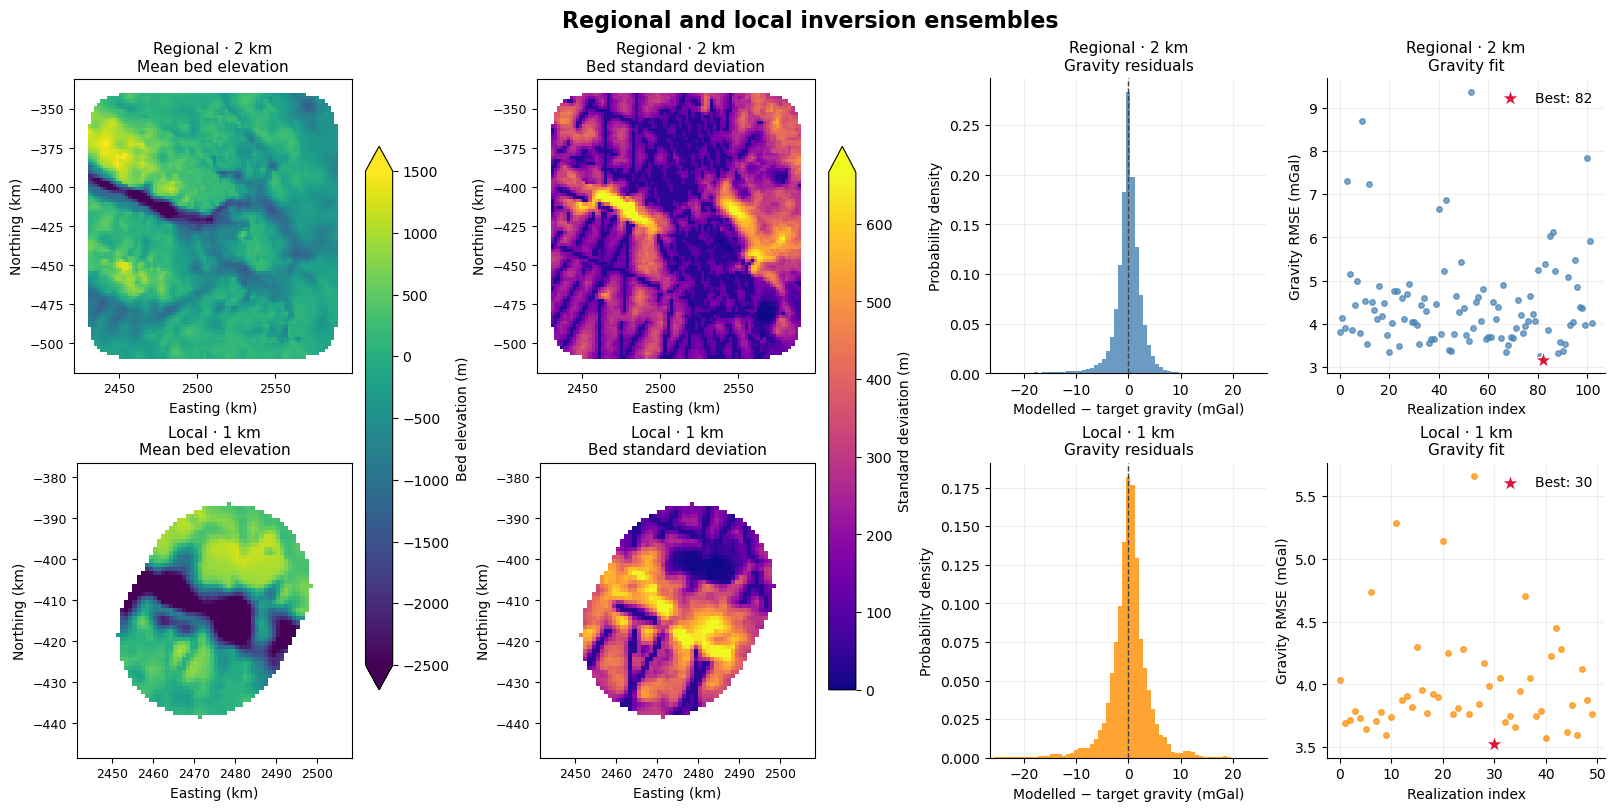

In [34]:
runs = [("Regional · 2 km", ds_run_2k, regional),("Local · 1 km", ds_run_1k, local),]
statistics = []

for title, grid, results in runs:
    beds = results["beds"]
    mask = grid.inv_msk.values.astype(bool)

    mean_bed = np.where(mask, np.nanmean(beds, axis=0), np.nan)
    std_bed = np.where(mask, np.nanstd(beds, axis=0), np.nan)

    gravity_residuals = (np.asarray(results["grav"]) - np.asarray(results["target"]))
    residuals_flat = gravity_residuals.reshape(len(beds), -1)
    gravity_rmse = np.sqrt(np.nanmean(residuals_flat**2, axis=1))
    statistics.append((title, grid, mean_bed, std_bed, residuals_flat, gravity_rmse))


bed_norm = Normalize(vmin=-2500, vmax=1500)
std_values = np.concatenate([item[3][np.isfinite(item[3])] for item in statistics])
std_norm = Normalize(vmin=0, vmax=np.percentile(std_values, 99))
residual_values = np.concatenate([item[4][np.isfinite(item[4])] for item in statistics])
residual_limit = np.percentile(np.abs(residual_values), 99.5)
residual_bins = np.linspace(-residual_limit, residual_limit, 70)

fig, axes = plt.subplots(2, 4,figsize=(16, 8),layout="constrained",)

for row, (title, grid, mean_bed, std_bed, residuals, gravity_rmse) in enumerate(statistics):
    x = grid.x.values / 1000
    y = grid.y.values / 1000
    colour = ["steelblue", "darkorange"][row]

    # Ensemble mean bed.
    im_mean = axes[row, 0].pcolormesh(x, y, mean_bed,norm=bed_norm,shading="auto",rasterized=True,)

    # Ensemble spread.
    im_std = axes[row, 1].pcolormesh(x, y, std_bed,cmap="plasma",norm=std_norm,shading="auto",rasterized=True,)

    for ax in axes[row, :2]:
        ax.set_aspect("equal")
        ax.set_xlabel("Easting (km)")
        ax.set_ylabel("Northing (km)")
        ax.tick_params(labelsize=9)

    # Pooled gravity residuals from all realizations.
    finite_residuals = residuals[np.isfinite(residuals)]

    axes[row, 2].hist(finite_residuals,bins=residual_bins,density=True,color=colour,alpha=0.8,)
    axes[row, 2].axvline(0, color="0.25", linestyle="--", linewidth=1)
    axes[row, 2].set(xlabel="Modelled − target gravity (mGal)",ylabel="Probability density",xlim=(-residual_limit, residual_limit),)

    # Gravity fit of each realization.
    best_index = int(np.nanargmin(gravity_rmse))
    axes[row, 3].plot(np.arange(len(gravity_rmse)),gravity_rmse,"o",color=colour,markersize=4,alpha=0.7,)
    axes[row, 3].scatter(best_index,gravity_rmse[best_index],marker="*",s=180,color="crimson",edgecolor="white",zorder=5,label=f"Best: {best_index}",)
    axes[row, 3].set(xlabel="Realization index",ylabel="Gravity RMSE (mGal)",)
    axes[row, 3].legend(frameon=False)

    for ax in axes[row, 2:]:
        ax.grid(alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        
    mask = grid.inv_msk.values.astype(bool)
    rows, cols = np.where(mask)

    for ax in axes[row, :2]:
        ax.set_xlim(x[cols].min()-10, x[cols].max()+10)
        ax.set_ylim(y[rows].min()-10, y[rows].max()+10)

    for col, heading in enumerate(["Mean bed elevation","Bed standard deviation","Gravity residuals","Gravity fit",]):
        axes[row, col].set_title(f"{title}\n{heading}", fontsize=11)

fig.colorbar(im_mean,ax=axes[:, 0],label="Bed elevation (m)",shrink=0.8,extend="both",)
fig.colorbar(im_std,ax=axes[:, 1],label="Standard deviation (m)",shrink=0.8,extend="max",)
fig.suptitle("Regional and local inversion ensembles",fontsize=16,fontweight="bold",)

plt.show()

In [9]:
bestfit = "gravity"  # "gravity" or "radar"

def evaluate_results(results, grid):
    beds = results["beds"]
    mask = grid.inv_msk.values.astype(bool)
    reference = grid.bed.values

    rmse_radar = np.empty(len(beds))
    rmse_grav = np.empty(len(beds))

    # Process one realization at a time to limit memory use.
    for i in range(len(beds)):
        diff_bed = np.where(mask, beds[i] - reference, np.nan)
        diff_grav = results["grav"][i] - results["target"][i]

        rmse_radar[i] = np.sqrt(np.nanmean(diff_bed**2))
        rmse_grav[i] = np.sqrt(np.nanmean(diff_grav**2))

    index_radar = int(np.nanargmin(rmse_radar))
    index_grav = int(np.nanargmin(rmse_grav))

    return {"rmse_radar": rmse_radar,"rmse_grav": rmse_grav,"index_radar": index_radar,"index_gravity": index_grav,}


scores_local = evaluate_results(local, ds_run_1k)
scores_regional = evaluate_results(regional, ds_run_2k)

best_index_local = scores_local[f"index_{bestfit}"]
best_index_regional = scores_regional[f"index_{bestfit}"]

for name, scores, index in (("Local", scores_local, best_index_local),("Regional", scores_regional, best_index_regional),):
    print(f"{name}: selected index {index} ({bestfit}); "
          f"radar RMSE = {scores['rmse_radar'][index]:.2f} m, "
          f"gravity RMSE = {scores['rmse_grav'][index]:.2f} mGal")

Local: selected index 30 (gravity); radar RMSE = 41.78 m, gravity RMSE = 3.52 mGal
Regional: selected index 82 (gravity); radar RMSE = 39.29 m, gravity RMSE = 3.16 mGal


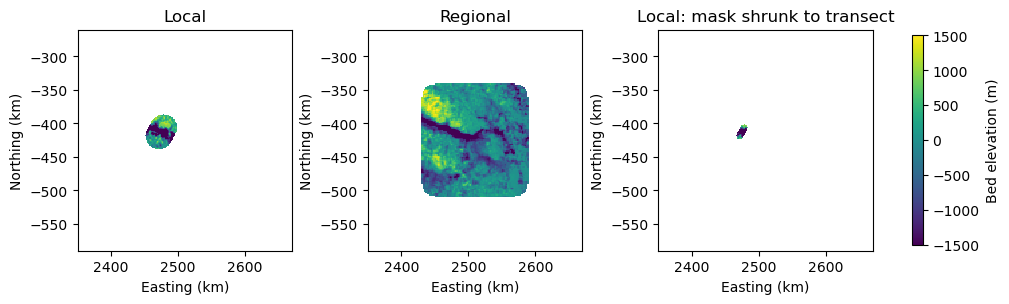

In [10]:
# Shrink the local mask by 15 km.
msk_local = ds_run_1k.inv_msk.values.astype(bool)
msk_regional = ds_run_2k.inv_msk.values.astype(bool)

dx = float(np.abs(np.diff(ds_run_1k.x.values)).mean())
dy = float(np.abs(np.diff(ds_run_1k.y.values)).mean())

dist = distance_transform_edt(msk_local, sampling=(dy, dx))
msk_shrunk = dist > 15_000

bed_local = local["beds"][best_index_local]
bed_regional = regional["beds"][best_index_regional]

# Keep separate difference arrays for later use.
diff_bed_best_local = np.where(msk_local, bed_local - ds_run_1k.bed.values, np.nan)
diff_bed_best_regional = np.where(msk_regional, bed_regional - ds_run_2k.bed.values, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)

panels = (
    (ds_run_1k, bed_local, msk_local, "Local"),
    (ds_run_2k, bed_regional, msk_regional, "Regional"),
    (ds_run_1k, bed_local, msk_shrunk, "Local: mask shrunk to transect"),)

for ax, (grid, bed, mask, title) in zip(axes, panels):
    image = ax.pcolormesh(grid.x / 1000,grid.y / 1000,np.where(mask, bed, np.nan),vmin=-1500,vmax=1500,shading="auto",)
    ax.set(title=title,xlabel="Easting (km)",ylabel="Northing (km)",aspect="equal",)

fig.colorbar(image, ax=axes, label="Bed elevation (m)", shrink=0.8)
plt.show()

In [11]:
grid_regional = ds_run_2k
grid_local = ds_run_1k

# Regional source coordinates.
xr_, yr_ = np.meshgrid(grid_regional.x.values, grid_regional.y.values)
points = np.column_stack((xr_.ravel(), yr_.ravel()))

# Local target coordinates
xl, yl = np.meshgrid(grid_local.x.values, grid_local.y.values)

# Interpolate all regional simulations onto the local grid.
interp_beds_regional_to_local = np.empty((len(regional["beds"]), *xl.shape))

for i, bed in enumerate(tqdm(regional["beds"], desc="Interpolating beds")):
    interp_beds_regional_to_local[i] = griddata(points,bed.ravel(),(xl, yl),method="cubic",)

# interp_bed_regional_to_local = (interp_beds_regional_to_local[best_index_regional])

Interpolating beds:   0%|          | 0/103 [00:00<?, ?it/s]

In [12]:
# Interpolate best regional result onto the BedMachine grid.
X_reg, Y_reg = np.meshgrid(grid_regional.x.values,grid_regional.y.values)
X_hr, Y_hr = np.meshgrid(ds.easting.values,ds.northing.values)

#interp_bed_regional_hr = griddata(np.column_stack((X_reg.ravel(), Y_reg.ravel())),
#    regional["beds"][best_index_regional].ravel(),(X_hr * 1000, Y_hr * 1000),method="linear")

In [13]:
'''
The 103 regional bed realizations are interpolated onto the local grid and paired with the 50 local realizations, 
reusing each local member two or three times. A fixed random seed makes the pairing reproducible. 
Within the local inversion mask, shrunk by 15 km, each regional bed is replaced by its assigned local bed.

The merged ensemble is resampled onto the finer BedMachine grid and Gaussian-smoothed near the insertion boundary. 
This retains variability from both ensembles, assuming regional and local realizations can be combined independently.

A separate best-fit composite combines the independently selected best regional and local beds using the same processing. 
It is saved separately because it is not necessarily a member of the paired ensemble.
'''

mask_valid = msk_shrunk.astype(bool)
n_regional = len(regional["beds"])
n_local = len(local["beds"])

rng = np.random.default_rng(42)

# Balanced sampling: each local member appears two or three times.
local_indices = np.tile(np.arange(n_local),int(np.ceil(n_regional / n_local)),)[:n_regional]
rng.shuffle(local_indices)

# Ensemble: 103 regional/local combinations.
merged_beds = interp_beds_regional_to_local.copy()
merged_beds[:, mask_valid] = (local["beds"][local_indices][:, mask_valid])

# Separate best composite.
merged_bed_best = (interp_beds_regional_to_local[best_index_regional].copy())
merged_bed_best[mask_valid] = (local["beds"][best_index_local][mask_valid])

In [14]:
# Interpolate best merged results onto the BedMachine grid.
points_local_km = np.column_stack((xl.ravel() / 1000,yl.ravel() / 1000,))

# Resample the paired ensemble.
merged_beds_hr = np.empty((len(merged_beds), *X_hr.shape))

for i, bed in enumerate(tqdm(merged_beds, desc="Resampling merged beds")):
    merged_beds_hr[i] = griddata(points_local_km,bed.ravel(),(X_hr, Y_hr),method="linear",)

# Resample the independently selected best-fit composite.
merged_bed_best_hr = griddata(points_local_km,merged_bed_best.ravel(),(X_hr, Y_hr),method="linear")

Resampling merged beds:   0%|          | 0/103 [00:00<?, ?it/s]

In [15]:
# Smooth without spreading NaNs into neighbouring valid cells.
bed_hr = merged_bed_best_hr
valid = np.isfinite(bed_hr)

numerator = gaussian_filter(np.where(valid, bed_hr, 0.0), sigma=3)
denominator = gaussian_filter(valid.astype(float), sigma=3)

smoothed_full = np.divide(numerator,denominator,out=np.full_like(numerator, np.nan),where=denominator > 0,)

# Transfer the local insertion mask onto the finer grid.
inv_mask_hr = griddata(np.column_stack((xl.ravel() / 1000, yl.ravel() / 1000)),mask_valid.ravel().astype(float),(X_hr, Y_hr),method="nearest",) > 0.5

# Outer edge band of the inserted local region.
edge_zone = (binary_dilation(inv_mask_hr, iterations=3) & ~inv_mask_hr)

# Smoothing weight decreases with distance from that band,
# extending onto both sides of the boundary.
blend_width = 10
if edge_zone.any():
    dist = distance_transform_edt(~edge_zone)
    weight = np.clip(1 - dist / blend_width, 0, 1)
else:
    weight = np.zeros_like(bed_hr)

blended_bed_best = (bed_hr * (1 - weight) + smoothed_full * weight)
blended_bed_best[~valid] = np.nan

grid_blended = xr.Dataset({"bed": (("y", "x"), blended_bed_best)},coords={"x": X_hr[0, :],"y": Y_hr[:, 0],},)
grid_blended.bed.attrs["units"] = "m"
grid_blended.x.attrs["units"] = "km"
grid_blended.y.attrs["units"] = "km"

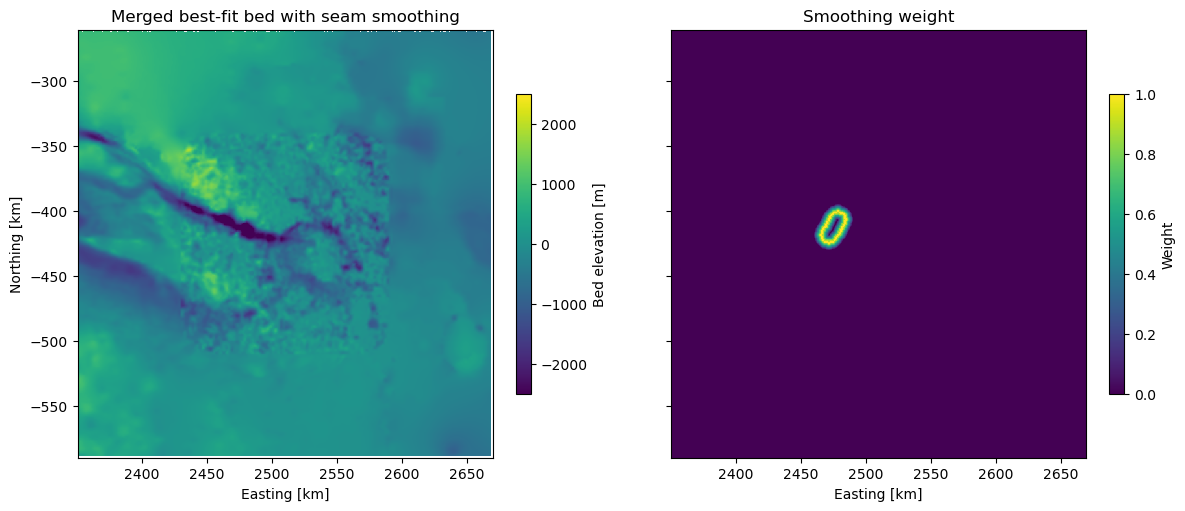

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5),sharex=True, sharey=True,constrained_layout=True)

image = axes[0].pcolormesh(X_hr, Y_hr, blended_bed_best,shading="auto", vmin=-2500, vmax=2500)
axes[0].set_title("Merged best-fit bed with seam smoothing")
fig.colorbar(image, ax=axes[0], label="Bed elevation [m]", shrink=0.7)

image_weight = axes[1].pcolormesh(X_hr, Y_hr, weight,shading="auto", vmin=0, vmax=1,)
axes[1].set_title("Smoothing weight")
fig.colorbar(image_weight, ax=axes[1], label="Weight", shrink=0.7)

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("Easting [km]")

axes[0].set_ylabel("Northing [km]")
plt.show()

In [17]:
# apply blending and smoothing to all beds
blended_beds = np.empty(merged_beds_hr.shape, dtype=float)

for i, bed in enumerate(tqdm(merged_beds_hr, desc="Smoothing beds")):
    valid = np.isfinite(bed)

    numerator = gaussian_filter(np.where(valid, bed, 0.0), sigma=3)
    denominator = gaussian_filter(valid.astype(float), sigma=3)
    smoothed = np.divide(numerator,denominator,out=np.full_like(numerator, np.nan),where=denominator > 0,)

    blended_beds[i] = bed * (1 - weight) + smoothed * weight
    blended_beds[i][~valid] = np.nan

Smoothing beds:   0%|          | 0/103 [00:00<?, ?it/s]

In [29]:
transformer = Transformer.from_crs("EPSG:3031", "EPSG:4326", always_xy=True)
lon, lat = transformer.transform(X_hr * 1000, Y_hr * 1000)

n_members = blended_beds.shape[0]

output_ds = xr.Dataset(
    data_vars={"bed_elevation": (("ensemble_member", "y", "x"),blended_beds),
               "best_bed_elevation": (("y", "x"),blended_bed_best)},
    coords={"ensemble_member": np.arange(n_members),
            "regional_index": ("ensemble_member", np.arange(n_members)),
            "local_index": ("ensemble_member", local_indices),
            "x": X_hr[0, :],
            "y": Y_hr[:, 0],
            "lon": (("y", "x"), lon),
            "lat": (("y", "x"), lat)},
    attrs={"description": (
        "Merged ensemble of 103 regional and 50 local bed realizations. "
        "Regional beds were interpolated onto the 1 km resolutionlocal grid and paired "
        "with local realizations, reusing each local member two or three "
        "times with reproducible shuffled assignments. Local elevations "
        "replaced regional elevations within the inversion mask shrunk "
        "by 15 km. Merged beds were resampled onto the finer BedMachine "
        "grid and Gaussian-smoothed near the insertion boundary. Source "
        "indices are stored for each member. A separate best-fit composite "
        "combines the independently selected best regional and local beds "
        "using the same processing.")})

output_ds.bed_elevation.attrs.update(units="m",long_name="Blended regional and local bed ensemble")
output_ds.best_bed_elevation.attrs.update(units="m",
    long_name="Composite of independently selected best-fitting beds",
    selected_regional_index=int(best_index_regional),
    selected_local_index=int(best_index_local))

output_ds.x.attrs.update(units="km", standard_name="projection_x_coordinate")
output_ds.y.attrs.update(units="km", standard_name="projection_y_coordinate")
output_ds.lon.attrs.update(units="degrees_east", standard_name="longitude")
output_ds.lat.attrs.update(units="degrees_north", standard_name="latitude")

output = pathlib.Path("results/merged/blended_beds.nc")
output.parent.mkdir(parents=True, exist_ok=True)

output_ds.to_netcdf(output,engine="netcdf4",encoding={name: {"zlib": True, "complevel": 4} for name in ("bed_elevation", "best_bed_elevation")})

In [23]:
# Have a look at the results
saved = xr.open_dataset("Results/Merged/blended_beds.nc")

ensemble = saved["bed_elevation"]
best_bed = saved["best_bed_elevation"]

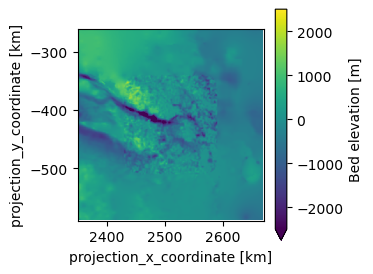

In [24]:
# Plot the best-fit composite.
best_bed.plot(x="x", y="y",figsize=(3, 3),vmin=-2500, vmax=2500,cbar_kwargs={"label": "Bed elevation [m]"})
plt.gca().set_aspect("equal")
plt.show()

In [25]:
# Select one ensemble member and check its source indices
member = ensemble.isel(ensemble_member=10)

print("Regional index:", saved.regional_index.isel(ensemble_member=10).item())
print("Local index:", saved.local_index.isel(ensemble_member=10).item())

bed_array = member.values
best_bed_array = best_bed.values

Regional index: 10
Local index: 2


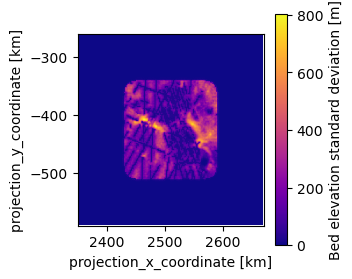

In [26]:
# Calculate maps of the ensemble mean and spread
mean_bed = ensemble.mean("ensemble_member")
std_bed = ensemble.std("ensemble_member")

std_bed.plot(x="x", y="y",figsize=(3, 3),cmap="plasma",cbar_kwargs={"label": "Bed elevation standard deviation [m]"},)
plt.gca().set_aspect("equal")
plt.show()

In [28]:
saved.close()